# AUTOMATIC CLEANING AND PROCESSING OF DIFFRACTION PATTERNS OF X-RAY

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks

## Variables

In [ ]:

D_THEOR= #interplanar theorycal distance
WAVELENGTH= #X-ray wave length
filepath=  #name of the file or the path

## Function for the data processing

In [32]:
def process_xrd_data(two_theta, intensity, reference_d):
    
    # Smoothing with Savitzky-Golay filter it will remove the noise at high hz
    # window_length has to be odd , polyorder is the degree of the polynomial
    smoothed_intensity = savgol_filter(intensity, window_length=15, polyorder=3)
    
    # Peak identification
    peaks, properties = find_peaks(smoothed_intensity, height=max(smoothed_intensity)*0.2, prominence=10)
    
    if len(peaks) == 0:
        return None, smoothed_intensity
    
    # find the index of the principal peak the one with max intensity
    main_peak_idx = peaks[np.argmax(properties['peak_heights'])]
    peak_2theta = two_theta[main_peak_idx]
    
    #Bragg's law and stress
    # n * lambda = 2 * d * sin(theta)  -> assumption: n=1

    theta_rad = np.radians(peak_2theta / 2.0)
    
    # calculation of the interplanar distance:
    d_exp = WAVELENGTH / (2 * np.sin(theta_rad))
    
    # calculation of the deformation in percentage:
    strain = ((d_exp - reference_d) / reference_d) * 100
    
    results = {
        '2theta_peak': peak_2theta,
        'd_exp': d_exp,
        'strain': strain,
        'peaks_indices': peaks,
        'main_peak_index': main_peak_idx
    }
    
    return results, smoothed_intensity

## Import data and make the file readable 

In [ ]:
def load_xrd_data(filepath):
    # comments='#' skip the line that start with a #
    # delimiter=',' the columns are separated by a comma
    data = np.genfromtxt(filepath, comments='#', delimiter=',')
    
    # we will extract the two columns
    two_theta = data[:, 0]
    intensity = data[:, 1]
    
    return two_theta, intensity

file_pirite = "ma09.dat"
x, y = load_xrd_data(file_pirite)


## Testing

--- REPORT---
position of principal peak (2θ): 35.575°
Sperimental interplanar (d): 7.6926 Å
Theorical distance of riferiment: 3.2000 Å
lattice deformation (Strain): 140.394% (Traction)


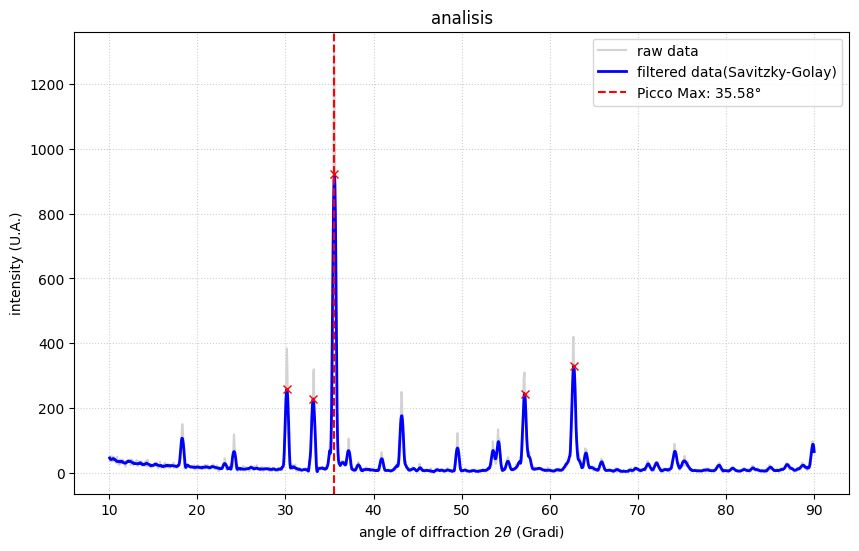

In [ ]:
if __name__ == "__main__":
    # you have to put the name of the file below
    sample_file =
    
    # 2. it will analyze the datas
    results, y_smoothed = process_xrd_data(x, y, D_THEOR)
    
    #visualizing and report
    plt.figure(figsize=(10, 6))
    plt.plot(x, y, color='lightgray', label='raw data')
    plt.plot(x, y_smoothed, color='blue', linewidth=2, label='filtered data(Savitzky-Golay)')
    
    if results:
        
        plt.plot(x[results['peaks_indices']], y_smoothed[results['peaks_indices']], "x", color='red')
        plt.axvline(x=results['2theta_peak'], color='red', linestyle='--', label=f'Picco Max: {results["2theta_peak"]:.2f}°')
        
        print("--- REPORT---")
        print(f"position of principal peak (2θ): {results['2theta_peak']:.3f}°")
        print(f"Experimental interplanar (d): {results['d_exp']:.4f} Å")
        print(f"Theoretical reference distance: {D_THEOR:.4f} Å")
        
        stress_status = "Traction" if results['strain'] > 0 else "Compression"
        print(f"lattice deformation (Strain): {results['strain']:.3f}% ({stress_status})")
        
    plt.title("analisys")
    plt.xlabel(r'angle of diffraction 2$\theta$ (Degrees)')
    plt.ylabel('intensity (U.A.)')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()